# L07 — How neural networks learn (v0.4 accepted)

**CH5330 Statistics · companion to the 19-slide lecture**  
**Four compact investigations:** (1) one forward pass and a hand-derived gradient; (2) finite-difference check; (3) two-moons training; (4) an untouched test set and confusion matrix.

This is **practice**, not a graded test. Work through the prediction prompts before executing each cell. Requires only NumPy and Matplotlib. Dataset: 200 two-moons points, noise 0.16, seed 42; split 140/30/30 as in L06.

## 1. From a prediction to a hidden-weight derivative

Take $z=wx+b$, $h=\tanh(z)$, $\hat y=vh+c$, $L=\tfrac12(\hat y-y)^2$. For $x=y=1$, $w=0.5$, $b=0$, $v=1$, $c=0$:

$$\frac{\partial L}{\partial w}=(\hat y-y)v(1-h^2)x.$$

**Predict before running:** Is $\partial L/\partial w$ positive or negative? Does increasing $w$ lower the loss?

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x, y, w, b, v, c, eta = 1., 1., 0.5, 0., 1., 0., 0.2

def scalar_forward(w):
    z = w*x+b
    h = np.tanh(z)
    yhat = v*h+c
    loss = 0.5*(yhat-y)**2
    return z,h,yhat,loss

z,h,yhat,loss=scalar_forward(w)
grad_w=(yhat-y)*v*(1-h*h)*x
new_w=w-eta*grad_w
print(f'h={h:.6f}, prediction={yhat:.6f}, loss={loss:.6f}')
print(f'dL/dw={grad_w:.6f}; one-weight update: {w:.4f} → {new_w:.6f}')
print(f'loss after one-weight update={scalar_forward(new_w)[-1]:.6f}')

h=0.462117, prediction=0.462117, loss=0.144659
dL/dw=-0.423017; one-weight update: 0.5000 → 0.584603
loss after one-weight update=0.112336


## 2. Verify the derivative without using the chain rule

A central finite difference uses two *forward* calculations: $[L(w+\varepsilon)-L(w-\varepsilon)]/(2\varepsilon)$.

**Prediction:** At $\varepsilon=10^{-5}$, how closely should it agree with your analytic result?

In [2]:
eps=1e-5
numeric=(scalar_forward(w+eps)[-1]-scalar_forward(w-eps)[-1])/(2*eps)
print(f'analytic gradient: {grad_w:+.8f}')
print(f'numeric  gradient: {numeric:+.8f}')
print(f'absolute difference: {abs(grad_w-numeric):.3e}')
assert abs(grad_w-numeric)<1e-7

analytic gradient: -0.42301674
numeric  gradient: -0.42301674
absolute difference: 2.448e-11


## 3. Learn the two moons

Now we apply the *same chain-rule logic* to a $2\to8\to1$ network. The hidden layer uses $\tanh$, and the output uses a sigmoid so that $p$ is a class-1 probability. For classification, minimise **binary cross-entropy**, not the squared-error teaching loss above. The network computes all gradients with NumPy (no automatic differentiation).

Training updates parameters; validation data are never used for gradient updates. The 30 test cases remain hidden until the final section.

Training: 140 | Validation: 30 | Test: 30


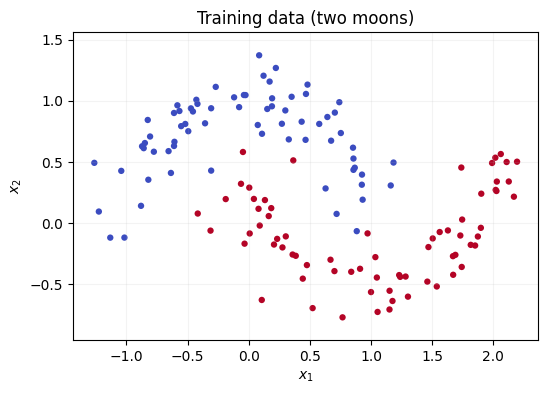

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# A fixed random seed gives the same synthetic data whenever you restart.
SEED = 42
rng = np.random.default_rng(SEED)

def make_two_moons(n_per_class=100, noise=0.16, seed=SEED):
    """Make two interlocking crescent-shaped groups of 2D points.

    This is a deliberately simple alternative to importing scikit-learn.
    The labels are 0 (upper crescent) and 1 (lower crescent).
    """
    random = np.random.default_rng(seed)
    t0 = random.uniform(0, np.pi, n_per_class)
    t1 = random.uniform(0, np.pi, n_per_class)
    upper = np.column_stack([np.cos(t0), np.sin(t0)])
    lower = np.column_stack([1 - np.cos(t1), 0.5 - np.sin(t1)])
    X = np.vstack([upper, lower])
    X += random.normal(0, noise, X.shape)
    y = np.array([0] * n_per_class + [1] * n_per_class)
    # Shuffle the data so that the two classes are interspersed.
    order = random.permutation(len(y))
    return X[order], y[order]

def split_data(X, y, seed=SEED):
    """Keep a test set separate. Only training points fit the model."""
    random = np.random.default_rng(seed + 1)
    # Split *within each class* so that small validation/test sets stay balanced.
    by_class = [random.permutation(np.where(y == label)[0]) for label in (0, 1)]
    train_ids, valid_ids, test_ids = [], [], []
    for indices in by_class:
        n_train = int(0.70 * len(indices))
        n_valid = int(0.15 * len(indices))
        train_ids.extend(indices[:n_train])
        valid_ids.extend(indices[n_train:n_train + n_valid])
        test_ids.extend(indices[n_train + n_valid:])
    return [(X[ids], y[ids]) for ids in (train_ids, valid_ids, test_ids)]

def show_points(X, y, title='Two moons'):
    plt.figure(figsize=(6, 4))
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=21, edgecolors='none')
    plt.xlabel('$x_1$'); plt.ylabel('$x_2$'); plt.title(title)
    plt.axis('equal'); plt.grid(alpha=0.15); plt.show()

X, y = make_two_moons()
(X_train, y_train), (X_val, y_val), (X_test, y_test) = split_data(X, y)
print(f'Training: {len(y_train)} | Validation: {len(y_val)} | Test: {len(y_test)}')
# Plot training observations
show_points(X_train, y_train, 'Training data (two moons)')
def sigmoid(z):
    """Logistic activation: maps any real number to (0, 1)."""
    z = np.clip(z, -40, 40)  # prevents overflow in exp for extreme inputs
    return 1 / (1 + np.exp(-z))

def binary_cross_entropy(y, probabilities):
    """Average loss for labels 0/1; clipping avoids log(0)."""
    p = np.clip(probabilities, 1e-10, 1 - 1e-10)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def accuracy(y, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    return np.mean(predictions == y)

def show_boundary(predict_probabilities, X, y, title):
    """Draw the p(class 1)=0.5 boundary of any binary classifier."""
    xmin, xmax = X[:, 0].min() - 0.3, X[:, 0].max() + 0.3
    ymin, ymax = X[:, 1].min() - 0.3, X[:, 1].max() + 0.3
    xs = np.linspace(xmin, xmax, 90)
    ys = np.linspace(ymin, ymax, 90)
    xx, yy = np.meshgrid(xs, ys)
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    probs = predict_probabilities(grid).reshape(xx.shape)
    plt.figure(figsize=(6, 4))
    plt.contourf(xx, yy, probs, levels=np.linspace(0, 1, 11), cmap='coolwarm', alpha=0.32)
    plt.contour(xx, yy, probs, levels=[0.5], colors='black', linewidths=1.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=17, edgecolors='none')
    plt.xlabel('$x_1$'); plt.ylabel('$x_2$'); plt.title(title)
    plt.axis('equal'); plt.show()
def create_network(hidden_units=8, seed=SEED):
    random = np.random.default_rng(seed)
    return {
        'W1': random.normal(0, 0.8, (2, hidden_units)),
        'b1': np.zeros(hidden_units),
        'W2': random.normal(0, 0.4, (hidden_units, 1)),
        'b2': np.zeros(1),
    }

def forward(X, net):
    H = np.tanh(X @ net['W1'] + net['b1'])
    p = sigmoid(H @ net['W2'] + net['b2']).ravel()
    return H, p

def gradients(X, y, net):
    """Return gradients of average BCE loss, one array per parameter."""
    H, p = forward(X, net)
    n = len(y)
    dZ2 = (p - y)[:, None] / n
    dW2 = H.T @ dZ2
    db2 = dZ2.sum(axis=0)
    dH = dZ2 @ net['W2'].T
    dZ1 = dH * (1 - H**2)
    dW1 = X.T @ dZ1
    db1 = dZ1.sum(axis=0)
    return {'W1': dW1, 'b1': db1, 'W2': dW2, 'b2': db2}

def gradient_step(net, grad, learning_rate):
    """Update parameters. This is gradient descent, not another model."""
    for key in net:
        net[key] -= learning_rate * grad[key]

def train_network(X, y, hidden_units=8, learning_rate=0.7, steps=2200):
    net = create_network(hidden_units)
    losses = []
    for step in range(steps):
        if step % 50 == 0:
            losses.append(binary_cross_entropy(y, forward(X, net)[1]))
        grad = gradients(X, y, net)
        gradient_step(net, grad, learning_rate)
    return net, losses



Final training loss: 0.0287
Final validation loss: 0.1537
Validation accuracy: 0.967


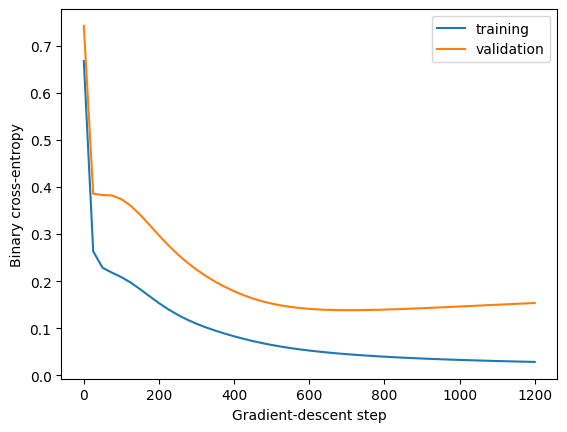

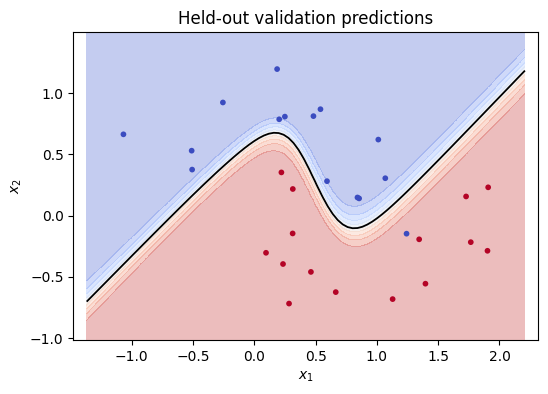

In [4]:
# FIXED BASELINE: try other learning rates only after recording this result.
learning_rate, steps, hidden_units = 0.7, 1200, 8
net=create_network(hidden_units)
train_curve=[]; valid_curve=[]; checkpoints=[]
for step in range(steps+1):
    if step%25==0:
        checkpoints.append(step)
        train_curve.append(binary_cross_entropy(y_train,forward(X_train,net)[1]))
        valid_curve.append(binary_cross_entropy(y_val,forward(X_val,net)[1]))
    if step<steps:
        gradient_step(net,gradients(X_train,y_train,net),learning_rate)

print('Final training loss:', round(train_curve[-1],4))
print('Final validation loss:',round(valid_curve[-1],4))
print('Validation accuracy:',round(accuracy(y_val,forward(X_val,net)[1]),3))
plt.plot(checkpoints,train_curve,label='training')
plt.plot(checkpoints,valid_curve,label='validation')
plt.xlabel('Gradient-descent step');plt.ylabel('Binary cross-entropy')
plt.legend();plt.show()
show_boundary(lambda X:forward(X,net)[1],X_val,y_val,'Held-out validation predictions')

## 4. Once-only test evaluation

**Before running:** decide whether your validation results justify using this trained model. Do not repeatedly tune the model to its *test* results.

The rows of the confusion matrix are **true classes** 0/1; columns are **predicted classes** 0/1. Accuracy is $(TN+TP)/N$. Since the test set contains only 30 observations, treat the result as an estimate with sampling uncertainty.

In [5]:
p_test=forward(X_test,net)[1]
pred=(p_test>=0.5).astype(int)
TN=int(((y_test==0)&(pred==0)).sum())
FP=int(((y_test==0)&(pred==1)).sum())
FN=int(((y_test==1)&(pred==0)).sum())
TP=int(((y_test==1)&(pred==1)).sum())
confusion=np.array([[TN,FP],[FN,TP]])
print('Confusion matrix (true rows, predicted columns):')
print(confusion)
print(f'Test accuracy = {(TN+TP)/len(y_test):.3f} ({TN+TP}/{len(y_test)})')
assert confusion.sum()==len(y_test)==30

Confusion matrix (true rows, predicted columns):
[[15  0]
 [ 1 14]]
Test accuracy = 0.967 (29/30)


### Three questions to take away

1. Why did the numerical derivative agree with the analytic gradient?
2. Why does a decreasing **training** loss not by itself establish generalisation?
3. Which would be more useful evidence for predicting new observations: a training-set confusion matrix or a test-set one? Why?

**Optional, not needed for the lecture:** in a wider network, the intermediate sensitivities become vectors and matrices. The idea of backward propagation remains exactly the same.